# What determines CFR ship selection?

In [2]:
import sys
sys.path.append(r"\Dev\Git\Woodsmith\post\run_report")

In [24]:
import woodsmith_run as wsr
import re
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
def read_log_multiseed(wr, log_name, date_range=None):
    dfs = {}
    for f in wr.outputs_path.glob(f"{wr.base_name}*{log_name}.log"):
        try:
            seed = re.findall(r".*_s(\d+).*", f.stem)[0]
        except IndexError:
            seed = f"{wr.median_seed}"
        df = wsr.read_log(f)
        df=df[df.iloc[:,0]>=wr.warmup_time]
        df.iloc[:,0] -= df.iloc[:,0].min()
        df = wsr.to_datetime_index(df)
        dfs[seed] = df

    df = pd.concat(dfs, axis=0)
    if date_range is not None:
        idx = pd.IndexSlice
        df = df.loc[idx[:,date_range[0]:date_range[-1]],:]
    return df


def ship_data_multi_seed(wr, date_range=None):
    dfs = {}
    log_name = "ShipDepart"
    prods = "Granule Chip Coarse".split()
    for f in wr.outputs_path.glob(f"{wr.base_name}*{log_name}.log"):
        try:
            seed = re.findall(r".*_s(\d+).*", f.stem)[0]
        except IndexError:
            seed = f"median"
        df = read_log(f)
        df=df[df.iloc[:,0]>=wr.warmup_time]
        df.iloc[:,0] -= df.iloc[:,0].min()
        df = to_datetime_index(df)
        prod_col = df.columns[df.columns.str.contains("MaterialList(1)", regex=False)][0]
        grade_col = df.columns[df.columns.str.contains('Chem.*"PH"', regex=True)][0]
        df = df[df[prod_col].isin(prods)].copy()
        dfs[seed] = df

    df_ship = pd.concat(dfs, axis=0)
    if date_range is not None:
        idx = pd.IndexSlice
        df_ship = df_ship.loc[idx[:,date_range[0]:date_range[-1]],:]
    return df_ship

In [4]:
run = wsr.load_single_run(r"C:\JSPRuns\20261014104426-3rd_party_cfr")

INFO:root:Using outputs path C:\JSPRuns\20261014104426-3rd_party_cfr\Outputs\3rd_party_cfr
INFO:root:Found 51 cfg files in C:\JSPRuns\20261014104426-3rd_party_cfr\Inputs\3rd_party_cfr
INFO:root:Found 51 dat files in C:\JSPRuns\20261014104426-3rd_party_cfr\Outputs\3rd_party_cfr, combined


In [12]:
run_old = wsr.load_single_run(r"C:\JSPRuns\20261008104728-CFR_overship_20_exponential")

INFO:root:Using outputs path C:\JSPRuns\20261008104728-CFR_overship_20_exponential\Outputs\CFR_overship_20_exponential
INFO:root:Found 51 cfg files in C:\JSPRuns\20261008104728-CFR_overship_20_exponential\Inputs\CFR_overship_20_exponential
INFO:root:Found 51 dat files in C:\JSPRuns\20261008104728-CFR_overship_20_exponential\Outputs\CFR_overship_20_exponential, combined


In [66]:
dfport_ = {"new":read_log_multiseed(run, "PortStocksAndChemistry"),
           "old":read_log_multiseed(run_old, "PortStocksAndChemistry")}

dfport = pd.concat(dfport_,axis=0)

In [67]:
dfport.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 3574182 entries, ('new', '49', Timestamp('2037-01-01 00:00:00')) to ('old', '9', Timestamp('2038-01-01 00:00:00'))
Data columns (total 12 columns):
 #   Column                                        Dtype  
---  ------                                        -----  
 0   [PortStockpileGranule_Shed1].Contents / 1[t]  float64
 1   [PortStockpileGranule_Shed1].Chemistry("PH")  float64
 2   [PortStockpileCoarse_Shed1].Contents / 1[t]   float64
 3   [PortStockpileCoarse_Shed1].Chemistry("PH")   float64
 4   [PortStockpileChip_Shed1].Contents / 1[t]     float64
 5   [PortStockpileChip_Shed1].Chemistry("PH")     float64
 6   [PortStockpileGranule_Shed2].Contents / 1[t]  float64
 7   [PortStockpileGranule_Shed2].Chemistry("PH")  float64
 8   [PortStockpileCoarse_Shed2].Contents / 1[t]   float64
 9   [PortStockpileCoarse_Shed2].Chemistry("PH")   float64
 10  [PortStockpileChip_Shed2].Contents / 1[t]     float64
 11  [PortStockpileChip_Shed2].Chem

In [68]:
cols=list(dfport.columns)+["level_0"]
dfp=dfport.xs('1',level=1).reset_index().loc[:,cols]

In [80]:
d2=dfport.xs('49',level=1)
#d2 = pd.concat([dfport.xs('18',level=1), dfport.xs('median',level=1)])
d2 = d2.loc[:,d2.columns.str.contains("Contents") & d2.columns.str.contains("Shed1")]/1000
d2=d2.rename(columns=lambda x: re.findall(r'PortStockpile(\w+)_.*',x)[0])
d2=d2.stack().reset_index()
d2.columns = "run time prod kt".split()

([0, 1, 2], [Text(0, 0, 'Granule'), Text(1, 0, 'Coarse'), Text(2, 0, 'Chip')])

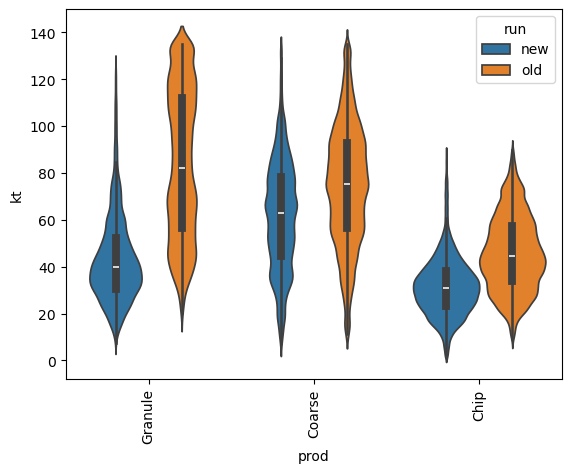

In [81]:
sns.violinplot(data=d2,x="prod",y="kt",hue="run")
plt.xticks(rotation=90)

In [95]:
avg_ship_sizes = {"Granule": 16.2,
                  "Chip": 31.3,
                  "Coarse": 78}

d3 = d2>0
for col in d2.columns:
    d3[col] = d2[col] > avg_ship_sizes[col]

<Axes: xlabel='prod', ylabel='n'>

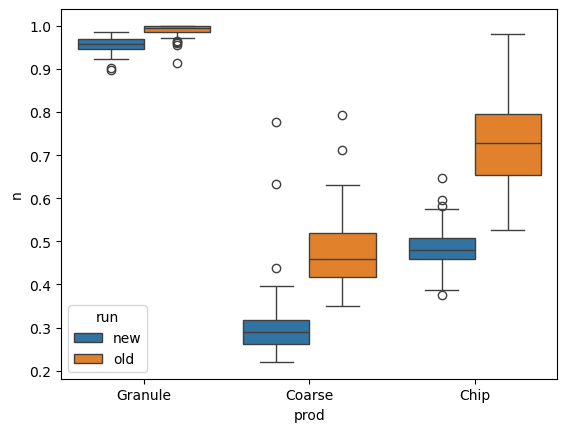

In [104]:
d4 = d3.groupby(level=[0,1]).mean().stack().reset_index()
d4.columns = "run seed prod n".split()
d4
sns.boxplot(data=d4, x="prod", y="n", hue="run")


In [83]:
d2 = dfport.loc[:,dfport.columns.str.contains("Contents") & dfport.columns.str.contains("Shed1")]/1000
d2=d2.rename(columns=lambda x: re.findall(r'PortStockpile(\w+)_.*',x)[0])
d2diff=(d2.xs('new')-d2.xs('old'))
d2diff.describe()

,Granule,Coarse,Chip
count,1.787091e+06,1.787091e+06,1.787091e+06
mean,-2.963763e+01,-1.078503e+01,-1.054364e+01
std,3.082761e+01,2.949758e+01,1.719568e+01
min,-1.282440e+02,-1.271032e+02,-8.014270e+01
25%,-5.161481e+01,-3.012641e+01,-2.219525e+01
50%,-2.448398e+01,-9.851895e+00,-9.072520e+00
75%,-6.007734e+00,8.436152e+00,2.000953e+00
max,7.735291e+01,1.143391e+02,7.054347e+01


In [ ]:
from scipy.stats import ttest_1samp

In [89]:
for col in d2diff.columns:
    d = d2diff[col]
    result = ttest_1samp(d, popmean=0)

    print(f"Effect for {col}:", d.mean())
    print("  p-value:", result.pvalue)
    print("  95% CI:", result.confidence_interval())


Effect for Granule: -29.63762876387242
  p-value: 0.0
  95% CI: ConfidenceInterval(low=-29.68282630997537, high=-29.592431217769473)
Effect for Coarse: -10.785025830486532
  p-value: 0.0
  95% CI: ConfidenceInterval(low=-10.828273380752195, high=-10.741778280220869)
Effect for Chip: -10.543641436760149
  p-value: 0.0
  95% CI: ConfidenceInterval(low=-10.568852686155598, high=-10.5184301873647)


In [94]:
d2.unstack(level=0).describe()

Granule                      Coarse                        Chip  \
                new           old           new           old           new   
count  1.787091e+06  1.787091e+06  1.787091e+06  1.787091e+06  1.787091e+06   
mean   4.563717e+01  7.527480e+01  6.568236e+01  7.646738e+01  3.202199e+01   
std    2.396520e+01  3.435928e+01  2.550707e+01  2.736204e+01  1.301964e+01   
min    9.967116e-01  1.734773e+00  1.940516e-01  5.415283e-01  2.480326e-01   
25%    2.921491e+01  4.610299e+01  4.702634e+01  5.680469e+01  2.295048e+01   
50%    4.026591e+01  7.034858e+01  6.539505e+01  7.633177e+01  3.083010e+01   
75%    5.608982e+01  1.056833e+02  8.223133e+01  9.490867e+01  3.905353e+01   
max    1.350000e+02  1.350000e+02  1.350000e+02  1.350000e+02  9.000000e+01   

                     
                old  
count  1.787091e+06  
mean   4.256563e+01  
std    1.671992e+01  
min    5.432893e-01  
25%    3.011340e+01  
50%    4.029513e+01  
75%    5.381178e+01  
max    9.000000e+01

In [93]:
d2.unstack(level=0)

Granule                 Coarse             \
                              new         old        new        old   
  this.SimTime/1[h]                                                   
1 2037-01-01 00:00:00  113.017853  135.000000  80.577310  96.523777   
  2037-01-01 00:15:00  113.196878  135.000000  80.577310  96.973777   
  2037-01-01 00:30:00  113.375903  135.000000  80.595577  97.423777   
  2037-01-01 00:45:00  113.554928  135.000000  80.595577  97.873777   
  2037-01-01 01:00:00  113.733953  135.000000  80.813416  97.988274   
...                           ...         ...        ...        ...   
9 2037-12-31 23:00:00   58.407254  101.278784  81.866250  88.686153   
  2037-12-31 23:15:00   58.505094  101.457809  82.316250  89.136153   
  2037-12-31 23:30:00   58.598108  101.636834  82.766250  89.471153   
  2037-12-31 23:45:00   58.687621  101.815859  83.216250  89.471153   
  2038-01-01 00:00:00   58.777133  101.994884  83.666250  89.471153   

                            Chip             
                             new        old  
  this.SimTime/1[h]                          
1 2037-01-01 00:00:00  68.080833  57.226727  
  2037-01-01 00:15:00  68.080833  57.226727  
  2037-01-01 00:30:00  68.080833  57.226727  
  2037-01-01 00:45:00  68.080833  57.226727  
  2037-01-01 01:00:00  68.080833  57.226727  
...                          ...        ...  
9 2037-12-31 23:00:00  65.364723  78.952920  
  2037-12-31 23:15:00  65.364723  78.952920  
  2037-12-31 23:30:00  65.364723  78.952920  
  2037-12-31 23:45:00  65.364723  79.178121  
  2038-01-01 00:00:00  65.364723  79.628121  

[1787091 rows x 6 columns]